In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style= "darkgrid", color_codes = True)
from tensorflow.keras.applications import ResNet50V2 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense, Flatten, Dropout, Input, GlobalAveragePooling2D
from keras.regularizers import l2
import warnings
warnings.filterwarnings('ignore')
tf.config.optimizer.set_jit(False)
# Vérifier si GPU est disponible
if tf.config.list_physical_devices('GPU'):
    # Permettre la croissance de la mémoire GPU
    for gpu in tf.config.experimental.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(gpu, True)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

2025-04-14 09:44:52.023056: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-14 09:44:52.098876: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744616692.142541    2743 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744616692.157762    2743 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744616692.215872    2743 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Define image size and other parameters
img_width, img_height = 128, 128
batchsize = 32
epochs = 6
num_of_class = 2
import tensorflow as tf
import os
import random

def create_balanced_three_class_dataset(directory, batch_size, img_size):
    normal_path = os.path.join(directory, 'NORMAL')
    pneumonia_path = os.path.join(directory, 'PNEUMONIA')

    # Récupération des fichiers et attribution des labels one-hot
    normal_files = [(os.path.join(normal_path, f), [1,0,0]) 
                    for f in os.listdir(normal_path) 
                    if f.endswith(('.jpeg', '.jpg', '.png'))]

    viral_files = [(os.path.join(pneumonia_path, f), [0,1,0]) 
                   for f in os.listdir(pneumonia_path) 
                   if 'virus' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    bacterial_files = [(os.path.join(pneumonia_path, f), [0,0,1]) 
                       for f in os.listdir(pneumonia_path) 
                       if 'bacteria' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    # Calcul du plus petit nombre d'images disponibles
    min_count = min(len(normal_files), len(viral_files), len(bacterial_files))

    # Équilibrer les classes
    random.shuffle(normal_files)
    random.shuffle(viral_files)
    random.shuffle(bacterial_files)

    normal_files = normal_files[:min_count]
    viral_files = viral_files[:min_count]
    bacterial_files = bacterial_files[:min_count]

    # Fusionner toutes les données
    all_data = normal_files + viral_files + bacterial_files
    random.shuffle(all_data)

    print(f"[{directory}] Normal: {len(normal_files)}, Viral: {len(viral_files)}, Bacterial: {len(bacterial_files)}")


    file_paths, labels = zip(*all_data)

    # Création du dataset
    def load_and_preprocess_image(file_path, label):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, img_size)
        img = img / 255.0
        return img, label

    dataset = tf.data.Dataset.from_tensor_slices((list(file_paths), list(labels)))
    dataset = dataset.map(load_and_preprocess_image)
    dataset = dataset.shuffle(buffer_size=len(all_data))
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return dataset


# Charger les datasets
img_size = (img_width, img_height)
train = create_balanced_three_class_dataset('chest_xray/train', batchsize, img_size)
validation = create_balanced_three_class_dataset('chest_xray/val', batchsize, img_size)
test = create_balanced_three_class_dataset('chest_xray/test', batchsize, img_size)

# Vérifier la forme des données
for images, labels in train.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Sample labels:", labels[0])  # Devrait montrer un vecteur one-hot de taille 3

[chest_xray/train] Normal: 1341, Viral: 1341, Bacterial: 1341


I0000 00:00:1744616695.206231    2743 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


[chest_xray/val] Normal: 8, Viral: 8, Bacterial: 8
[chest_xray/test] Normal: 148, Viral: 148, Bacterial: 148
Images shape: (32, 128, 128, 3)
Labels shape: (32, 3)
Sample labels: tf.Tensor([1 0 0], shape=(3,), dtype=int32)


2025-04-14 09:44:59.294404: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Format des labels: [1 0 0]
Label 0: [1.0, 0.0, 0.0]
Label 1: [1.0, 0.0, 0.0]
Label 2: [0.0, 1.0, 0.0]
Label 3: [0.0, 1.0, 0.0]


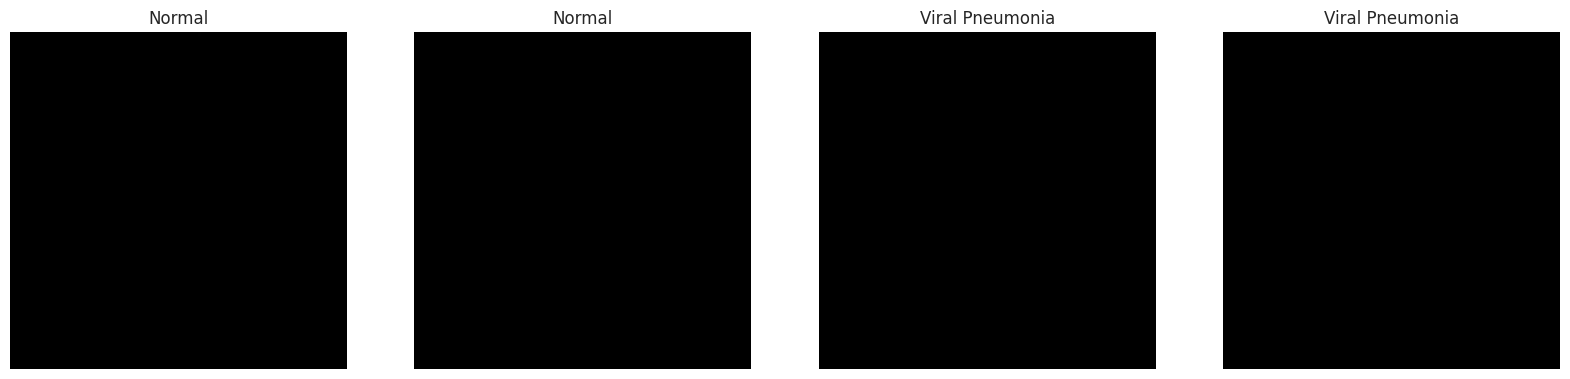

In [3]:
data_iterator = train.as_numpy_iterator()
batch = data_iterator.next()

# Afficher un exemple de label pour debug
print("Format des labels:", batch[1][0])

# Créer un dictionnaire pour convertir les labels one-hot en texte
label_dict = {
    '[1.0, 0.0, 0.0]': "Normal",
    '[0.0, 1.0, 0.0]': "Viral Pneumonia",
    '[0.0, 0.0, 1.0]': "Bacterial Pneumonia"
}

fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    # Convertir le label en string avec le bon format
    label_str = str([float(x) for x in batch[1][idx].tolist()])
    print(f"Label {idx}:", label_str)  # Debug
    label = label_dict.get(label_str, "Unknown")
    ax[idx].title.set_text(label)
    ax[idx].axis('off')

plt.show()

In [4]:
from tensorflow.keras.utils import to_categorical
# Définir une taille fixe pour toutes les images
IMG_SIZE = (128, 128)  # Taille standard pour VGG16

# Extracting Features and Labels
x_train = []
y_train = []
x_val = []
y_val = []
x_test = []
y_test = []

# Fonction pour traiter un batch
def process_batch(batch):
    features, labels = batch
    features = tf.image.resize(features, IMG_SIZE)
    return features.numpy(), labels.numpy()

# Traiter les données d'entraînement
for batch in train:
    features, labels = process_batch(batch)
    x_train.extend(features)
    y_train.extend(labels)

# Traiter les données de test
for batch in test:
    features, labels = process_batch(batch)
    x_test.extend(features)
    y_test.extend(labels)

# Traiter les données de validation
for batch in validation:
    features, labels = process_batch(batch)
    x_val.extend(features)
    y_val.extend(labels)

# Convertir en arrays numpy
x_train = np.array(x_train, dtype=np.float32)
x_val = np.array(x_val, dtype=np.float32)
x_test = np.array(x_test, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

# Normaliser les images
x_train = tf.image.resize(x_train, IMG_SIZE)
x_val = tf.image.resize(x_val, IMG_SIZE)
x_test = tf.image.resize(x_test, IMG_SIZE)


# Vérifier les shapes
print("Shape de x_train:", x_train.shape)
print("Shape de y_train:", y_train.shape)
print("Shape de x_val:", x_val.shape)
print("Shape de y_val:", y_val.shape)
print("Shape de x_test:", x_test.shape)
print("Shape de y_test:", y_test.shape)

# Vérifier les valeurs uniques dans les labels
print("\nValeurs uniques dans y_train:", np.unique(y_train, axis=0))

2025-04-14 09:45:07.191724: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-04-14 09:45:07.598117: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Shape de x_train: (4023, 128, 128, 3)
Shape de y_train: (4023, 3)
Shape de x_val: (24, 128, 128, 3)
Shape de y_val: (24, 3)
Shape de x_test: (444, 128, 128, 3)
Shape de y_test: (444, 3)

Valeurs uniques dans y_train: [[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [5]:
# check the shapes of 'x_train' and 'y_train':
print("Shape of 'x_train':", x_train.shape)
print("Shape of 'y_train':", y_train.shape)
print("Shape of 'x_val':", x_val.shape)
print("Shape of 'y_val':", y_val.shape)
print("Shape of 'x_test':", x_test.shape)
print("Shape of 'y_test':", y_test.shape)

Shape of 'x_train': (4023, 128, 128, 3)
Shape of 'y_train': (4023, 3)
Shape of 'x_val': (24, 128, 128, 3)
Shape of 'y_val': (24, 3)
Shape of 'x_test': (444, 128, 128, 3)
Shape of 'y_test': (444, 3)


In [6]:
def create_model():
    base_model = ResNet50V2 (weights='imagenet', 
                      include_top=False, 
                      input_shape=(128, 128, 3))

    base_model.trainable = False
    
    model = Sequential([
        base_model,
        Flatten(),
        Dropout(0.4),
        Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        Dense(3, activation='softmax')
    ])
    
    # Learning rate plus faible pour un meilleur apprentissage
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
    
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy', 'Precision', 'Recall']
    )

    model.summary()
    
    return model

Fold 1/5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 8,422,147 (32.13 MB)

...

  5/101 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - Precision: 0.4141 - Recall: 0.3991 - accuracy: 0.4148 - loss: 9.1888

I0000 00:00:1744616732.860979   17204 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


100/101 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - Precision: 0.6082 - Recall: 0.5896 - accuracy: 0.6039 - loss: 7.0227

2025-04-14 09:45:36.857055: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5702', 4 bytes spill stores, 4 bytes spill loads



101/101 ━━━━━━━━━━━━━━━━━━━━ 30s 165ms/step - Precision: 0.6090 - Recall: 0.5904 - accuracy: 0.6047 - loss: 7.0023 - val_Precision: 0.7295 - val_Recall: 0.6733 - val_accuracy: 0.7180 - val_loss: 4.6272 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - Precision: 0.7294 - Recall: 0.7008 - accuracy: 0.7149 - loss: 4.5366 - val_Precision: 0.7763 - val_Recall: 0.7329 - val_accuracy: 0.7578 - val_loss: 4.0486 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - Precision: 0.7615 - Recall: 0.7337 - accuracy: 0.7506 - loss: 3.9979 - val_Precision: 0.7682 - val_Recall: 0.7491 - val_accuracy: 0.7590 - val_loss: 3.7187 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - Precision: 0.7807 - Recall: 0.7601 - accuracy: 0.7710 - loss: 3.6281 - val_Precision: 0.7943 - val_Recall: 0.7578 - val_accuracy: 0.7839 - val_loss: 3.4078 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step 

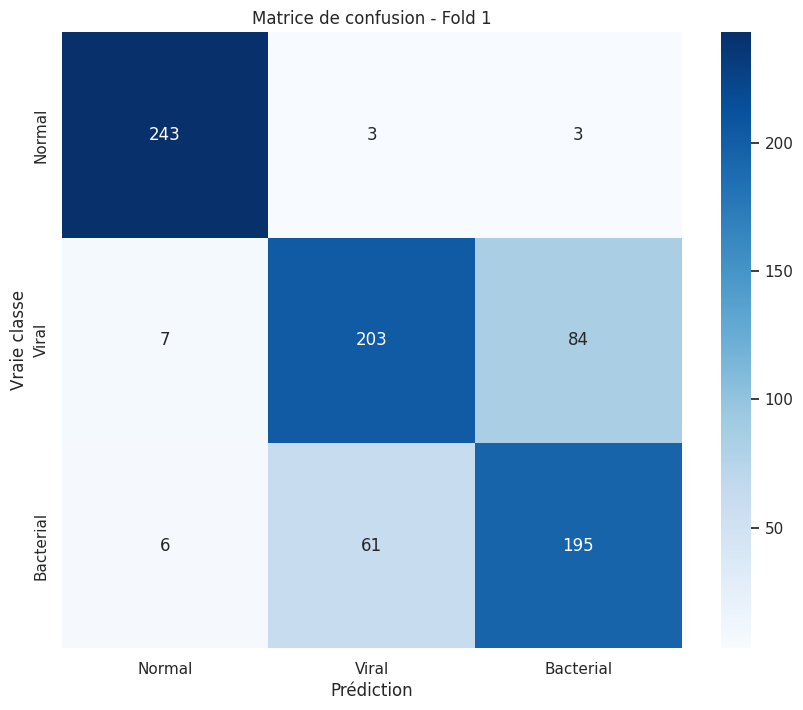


Métriques détaillées pour le Fold 1:

Classe: Normal
True Positives (TP): 243
True Negatives (TN): 543
False Positives (FP): 13
False Negatives (FN): 6
Precision: 0.9492
Recall: 0.9759

Classe: Viral
True Positives (TP): 203
True Negatives (TN): 447
False Positives (FP): 64
False Negatives (FN): 91
Precision: 0.7603
Recall: 0.6905

Classe: Bacterial
True Positives (TP): 195
True Negatives (TN): 456
False Positives (FP): 87
False Negatives (FN): 67
Precision: 0.6915
Recall: 0.7443

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.95      0.98      0.96       249
       Viral       0.76      0.69      0.72       294
   Bacterial       0.69      0.74      0.72       262

    accuracy                           0.80       805
   macro avg       0.80      0.80      0.80       805
weighted avg       0.80      0.80      0.80       805



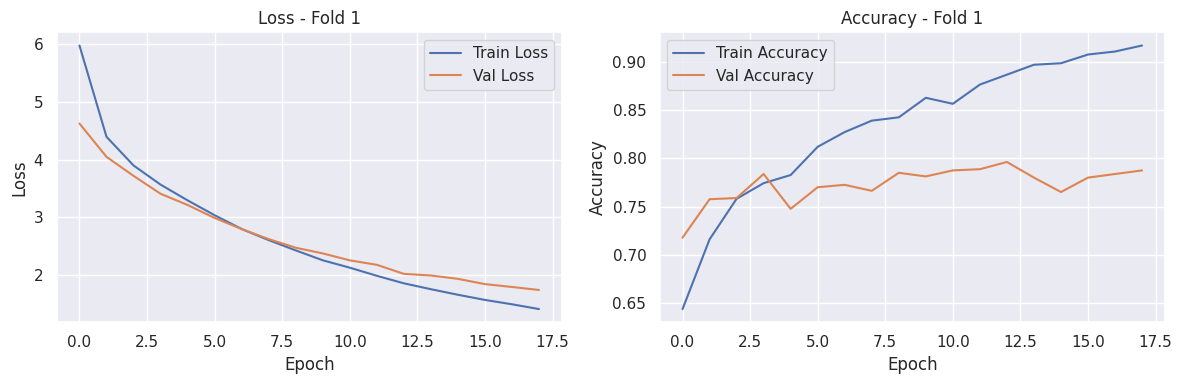

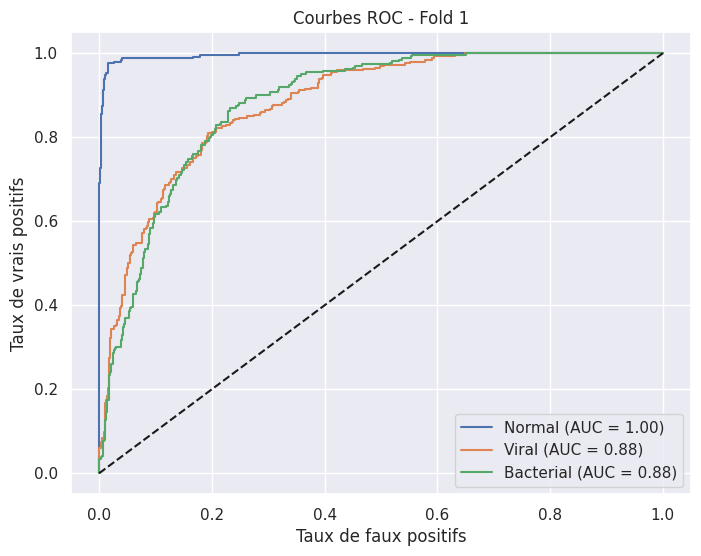

Fold 2/5


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 8,422,147 (32.13 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 17s 104ms/step - Precision: 0.5780 - Recall: 0.5562 - accuracy: 0.5674 - loss: 7.0318 - val_Precision: 0.7455 - val_Recall: 0.7130 - val_accuracy: 0.7292 - val_loss: 4.6908 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - Precision: 0.7384 - Recall: 0.7101 - accuracy: 0.7246 - loss: 4.6049 - val_Precision: 0.7695 - val_Recall: 0.7342 - val_accuracy: 0.7516 - val_loss: 4.0876 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - Precision: 0.7768 - Recall: 0.7480 - accuracy: 0.7638 - loss: 4.0107 - val_Precision: 0.7694 - val_Recall: 0.7255 - val_accuracy: 0.7478 - val_loss: 3.7689 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - Precision: 0.7736 - Recall: 0.7486 - accuracy: 0.7645 - loss: 3.6715 - val_Precision: 0.7506 - val_Recall: 0.7329 - val_accuracy: 0.7416 - val_loss: 3.5085 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s

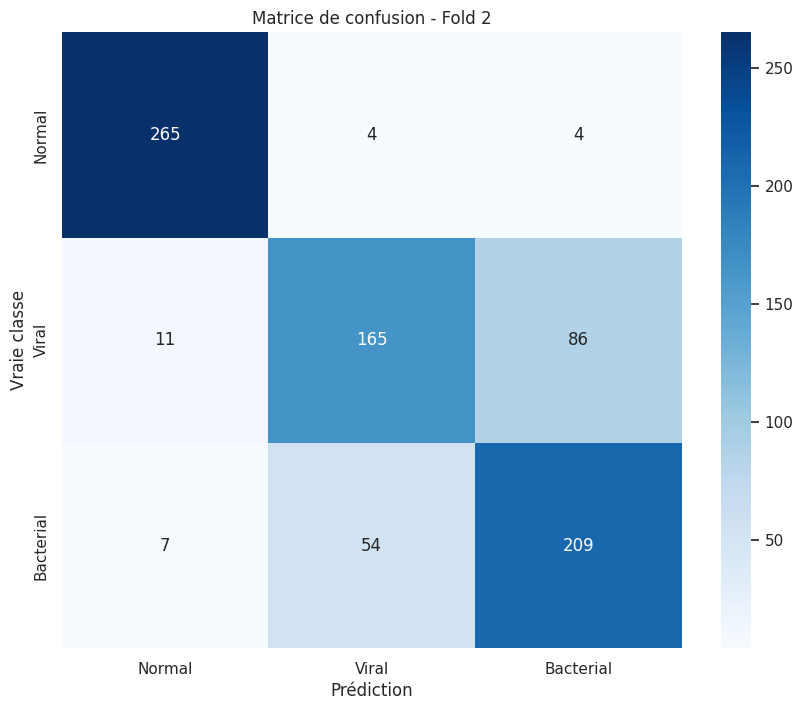


Métriques détaillées pour le Fold 2:

Classe: Normal
True Positives (TP): 265
True Negatives (TN): 514
False Positives (FP): 18
False Negatives (FN): 8
Precision: 0.9364
Recall: 0.9707

Classe: Viral
True Positives (TP): 165
True Negatives (TN): 485
False Positives (FP): 58
False Negatives (FN): 97
Precision: 0.7399
Recall: 0.6298

Classe: Bacterial
True Positives (TP): 209
True Negatives (TN): 445
False Positives (FP): 90
False Negatives (FN): 61
Precision: 0.6990
Recall: 0.7741

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.94      0.97      0.95       273
       Viral       0.74      0.63      0.68       262
   Bacterial       0.70      0.77      0.73       270

    accuracy                           0.79       805
   macro avg       0.79      0.79      0.79       805
weighted avg       0.79      0.79      0.79       805



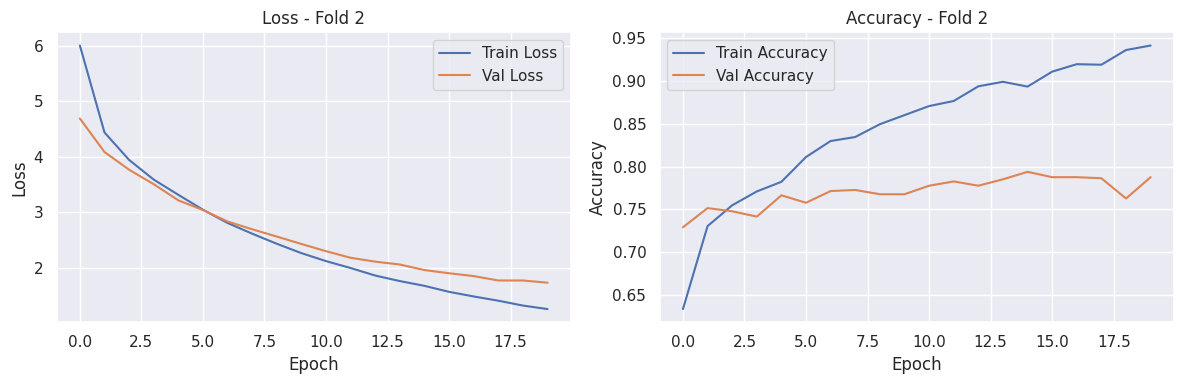

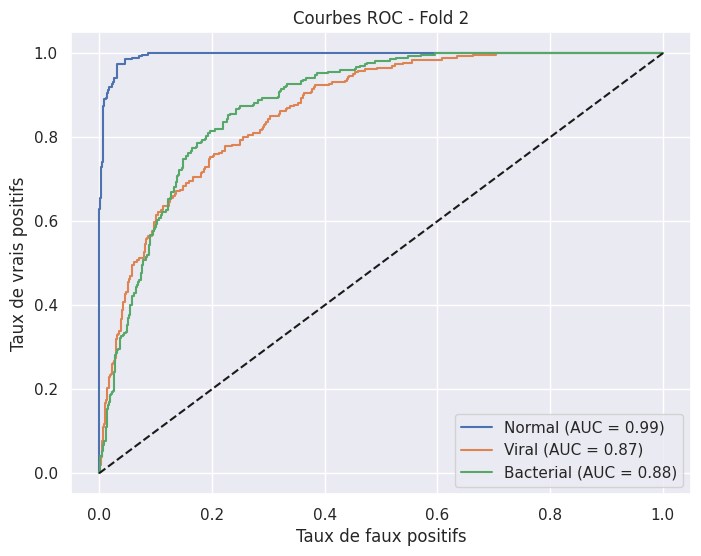

Fold 3/5


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 8,422,147 (32.13 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 19s 105ms/step - Precision: 0.6032 - Recall: 0.5867 - accuracy: 0.5947 - loss: 7.0523 - val_Precision: 0.7409 - val_Recall: 0.7106 - val_accuracy: 0.7267 - val_loss: 4.6274 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - Precision: 0.7331 - Recall: 0.7026 - accuracy: 0.7211 - loss: 4.4994 - val_Precision: 0.7714 - val_Recall: 0.7503 - val_accuracy: 0.7578 - val_loss: 4.0590 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - Precision: 0.7661 - Recall: 0.7401 - accuracy: 0.7522 - loss: 3.9550 - val_Precision: 0.7650 - val_Recall: 0.7280 - val_accuracy: 0.7565 - val_loss: 3.7056 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - Precision: 0.7794 - Recall: 0.7574 - accuracy: 0.7709 - loss: 3.5870 - val_Precision: 0.7700 - val_Recall: 0.7404 - val_accuracy: 0.7553 - val_loss: 3.4245 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s

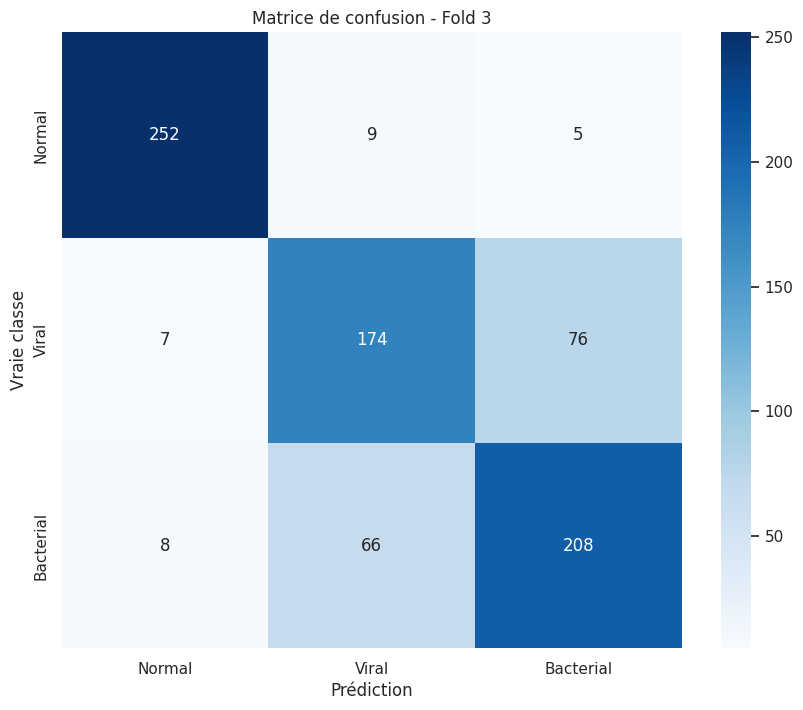


Métriques détaillées pour le Fold 3:

Classe: Normal
True Positives (TP): 252
True Negatives (TN): 524
False Positives (FP): 15
False Negatives (FN): 14
Precision: 0.9438
Recall: 0.9474

Classe: Viral
True Positives (TP): 174
True Negatives (TN): 473
False Positives (FP): 75
False Negatives (FN): 83
Precision: 0.6988
Recall: 0.6770

Classe: Bacterial
True Positives (TP): 208
True Negatives (TN): 442
False Positives (FP): 81
False Negatives (FN): 74
Precision: 0.7197
Recall: 0.7376

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.94      0.95      0.95       266
       Viral       0.70      0.68      0.69       257
   Bacterial       0.72      0.74      0.73       282

    accuracy                           0.79       805
   macro avg       0.79      0.79      0.79       805
weighted avg       0.79      0.79      0.79       805



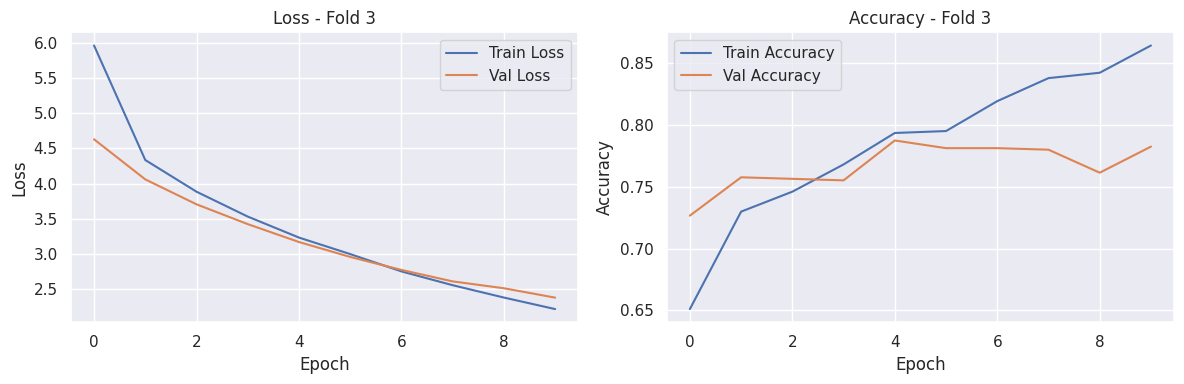

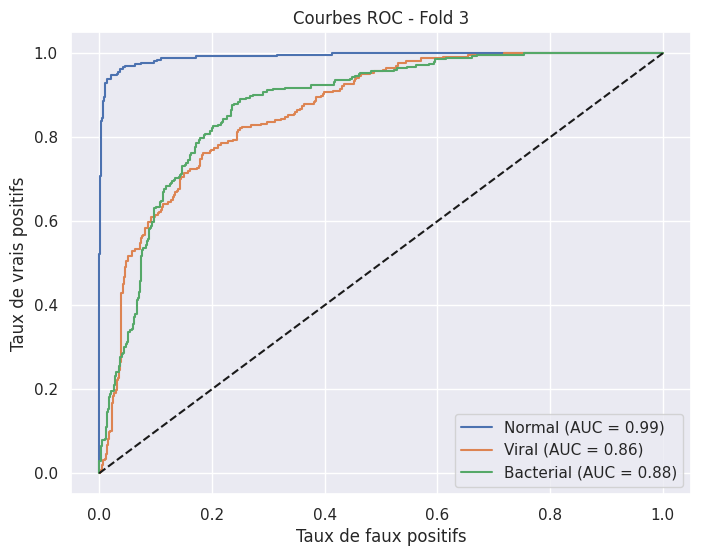

Fold 4/5


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 8,422,147 (32.13 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/20
100/101 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - Precision: 0.6039 - Recall: 0.5863 - accuracy: 0.5959 - loss: 7.0663

2025-04-14 09:50:03.636898: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5702', 4 bytes spill stores, 4 bytes spill loads

2025-04-14 09:50:06.404206: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.16GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


101/101 ━━━━━━━━━━━━━━━━━━━━ 25s 171ms/step - Precision: 0.6052 - Recall: 0.5875 - accuracy: 0.5971 - loss: 7.0456 - val_Precision: 0.7425 - val_Recall: 0.7065 - val_accuracy: 0.7276 - val_loss: 4.6638 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - Precision: 0.7567 - Recall: 0.7311 - accuracy: 0.7390 - loss: 4.5479 - val_Precision: 0.7798 - val_Recall: 0.7488 - val_accuracy: 0.7699 - val_loss: 4.0708 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - Precision: 0.7695 - Recall: 0.7462 - accuracy: 0.7589 - loss: 4.0222 - val_Precision: 0.7882 - val_Recall: 0.7637 - val_accuracy: 0.7749 - val_loss: 3.7138 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - Precision: 0.7641 - Recall: 0.7421 - accuracy: 0.7568 - loss: 3.6694 - val_Precision: 0.7737 - val_Recall: 0.7525 - val_accuracy: 0.7687 - val_loss: 3.4800 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step 

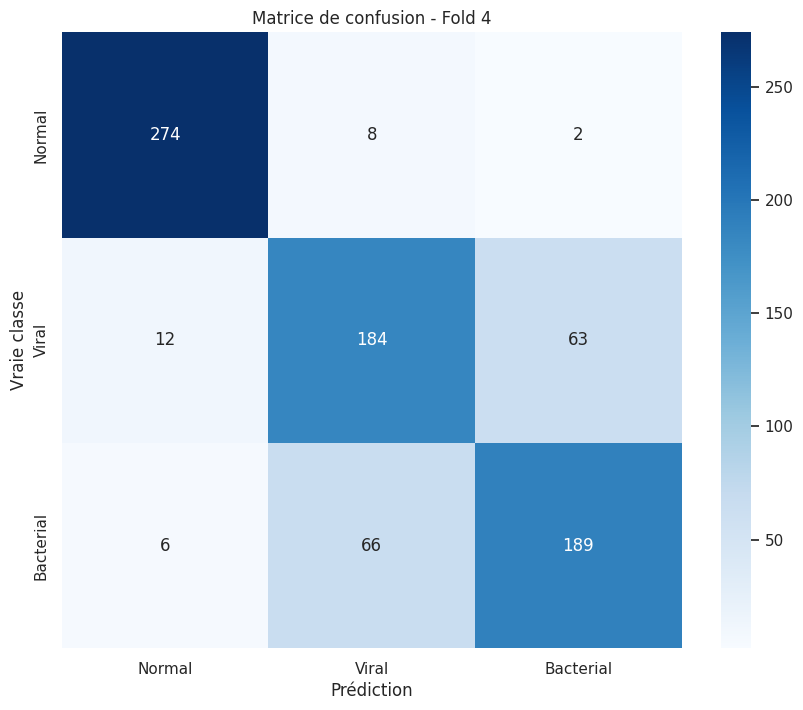


Métriques détaillées pour le Fold 4:

Classe: Normal
True Positives (TP): 274
True Negatives (TN): 502
False Positives (FP): 18
False Negatives (FN): 10
Precision: 0.9384
Recall: 0.9648

Classe: Viral
True Positives (TP): 184
True Negatives (TN): 471
False Positives (FP): 74
False Negatives (FN): 75
Precision: 0.7132
Recall: 0.7104

Classe: Bacterial
True Positives (TP): 189
True Negatives (TN): 478
False Positives (FP): 65
False Negatives (FN): 72
Precision: 0.7441
Recall: 0.7241

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.94      0.96      0.95       284
       Viral       0.71      0.71      0.71       259
   Bacterial       0.74      0.72      0.73       261

    accuracy                           0.80       804
   macro avg       0.80      0.80      0.80       804
weighted avg       0.80      0.80      0.80       804



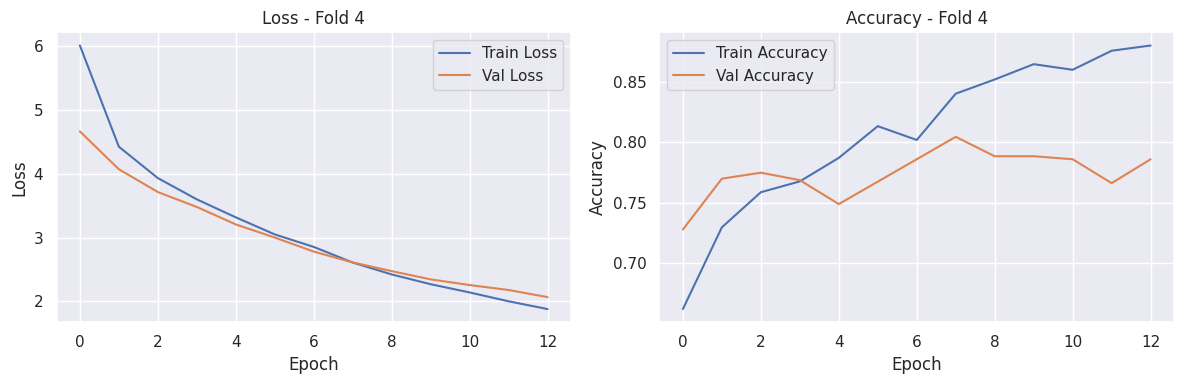

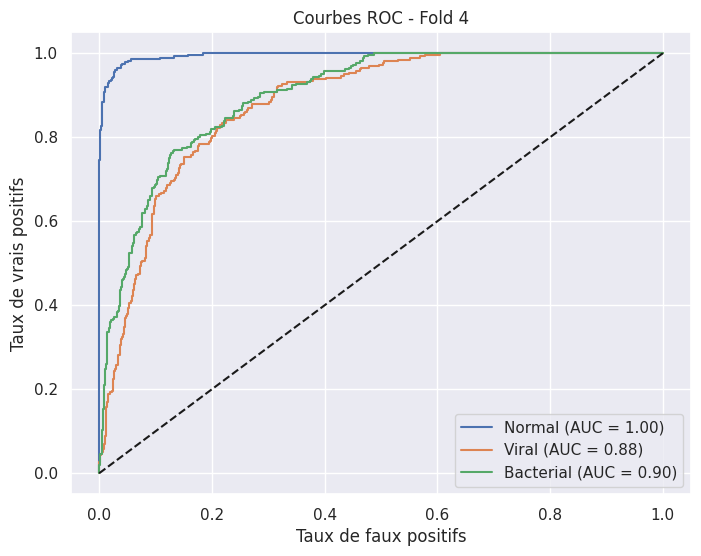

Fold 5/5


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 8,422,147 (32.13 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

Epoch 1/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 21s 125ms/step - Precision: 0.6057 - Recall: 0.5905 - accuracy: 0.5984 - loss: 7.1318 - val_Precision: 0.7497 - val_Recall: 0.7077 - val_accuracy: 0.7388 - val_loss: 4.7985 - learning_rate: 1.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - Precision: 0.7211 - Recall: 0.6949 - accuracy: 0.7108 - loss: 4.6772 - val_Precision: 0.7930 - val_Recall: 0.7338 - val_accuracy: 0.7624 - val_loss: 4.1855 - learning_rate: 1.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - Precision: 0.7666 - Recall: 0.7429 - accuracy: 0.7552 - loss: 4.1106 - val_Precision: 0.7858 - val_Recall: 0.7301 - val_accuracy: 0.7711 - val_loss: 3.8774 - learning_rate: 1.0000e-04
Epoch 4/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - Precision: 0.7746 - Recall: 0.7520 - accuracy: 0.7668 - loss: 3.7869 - val_Precision: 0.8132 - val_Recall: 0.7687 - val_accuracy: 0.7898 - val_loss: 3.5469 - learning_rate: 1.0000e-04
Epoch 5/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 4s

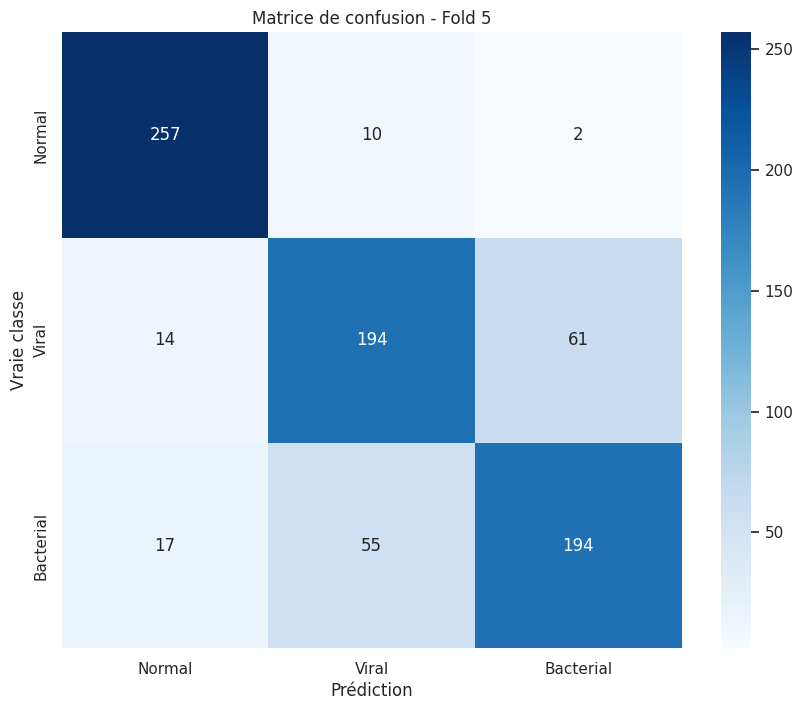


Métriques détaillées pour le Fold 5:

Classe: Normal
True Positives (TP): 257
True Negatives (TN): 504
False Positives (FP): 31
False Negatives (FN): 12
Precision: 0.8924
Recall: 0.9554

Classe: Viral
True Positives (TP): 194
True Negatives (TN): 470
False Positives (FP): 65
False Negatives (FN): 75
Precision: 0.7490
Recall: 0.7212

Classe: Bacterial
True Positives (TP): 194
True Negatives (TN): 475
False Positives (FP): 63
False Negatives (FN): 72
Precision: 0.7549
Recall: 0.7293

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.89      0.96      0.92       269
       Viral       0.75      0.72      0.73       269
   Bacterial       0.75      0.73      0.74       266

    accuracy                           0.80       804
   macro avg       0.80      0.80      0.80       804
weighted avg       0.80      0.80      0.80       804



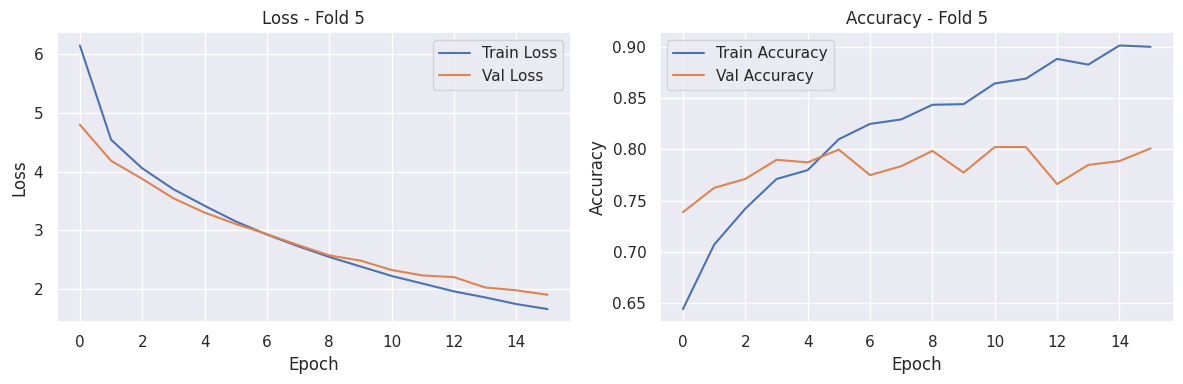

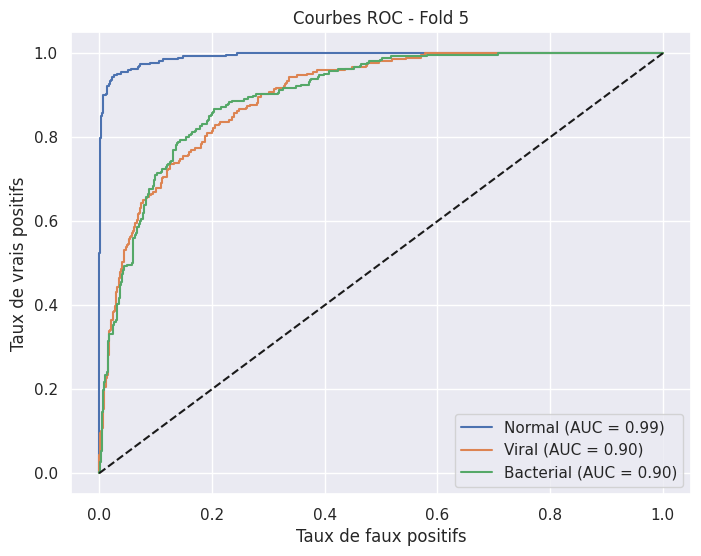


Résultats finaux:
Score moyen: 0.7969 (+/- 0.0061)


In [7]:
from sklearn.model_selection import KFold
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Convertir les données en numpy arrays si ce n'est pas déjà fait
x_train_np = x_train.numpy() if isinstance(x_train, tf.Tensor) else x_train
y_train_np = y_train.numpy() if isinstance(y_train, tf.Tensor) else y_train

# Définir le nombre de folds
n_folds = 5
batch_size = 32
epochs = 20
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
class_names = ['Normal', 'Viral', 'Bacterial']
# Boucle de validation croisée
val_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(x_train_np)):
    print(f'Fold {fold + 1}/{n_folds}')
    
    model = create_model()
    
    # Utiliser les arrays numpy pour l'indexation
    x_train_fold = x_train_np[train_idx]
    y_train_fold = y_train_np[train_idx]
    x_val_fold = x_train_np[val_idx]
    y_val_fold = y_train_np[val_idx]
    
    # Convertir en tensors pour l'entraînement si nécessaire
    x_train_fold = tf.convert_to_tensor(x_train_fold)
    y_train_fold = tf.convert_to_tensor(y_train_fold)
    x_val_fold = tf.convert_to_tensor(x_val_fold)
    y_val_fold = tf.convert_to_tensor(y_val_fold)
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True
    )
    
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001
    )

    history = model.fit(
        x_train_fold,
        y_train_fold,
        validation_data=(x_val_fold, y_val_fold),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping, reduce_lr]
    )
    
    val_score = model.evaluate(x_val_fold, y_val_fold, verbose=0)
    val_scores.append(val_score[1])
    
    print(f"Fold {fold + 1} - Accuracy: {val_score[1]:.4f}")
    
     # Matrice de confusion avec plus de détails
    y_pred = model.predict(x_val_fold)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_val_fold, axis=1)
    
    
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    
    # Calculer TP, TN, FP, FN pour chaque classe
    n_classes = 3
    metrics = {}
    
    for i in range(n_classes):
        TP = cm[i, i]
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP
        TN = np.sum(cm) - TP - FP - FN
        
        metrics[class_names[i]] = {
            'TP': TP,
            'TN': TN,
            'FP': FP,
            'FN': FN,
            'Precision': TP / (TP + FP) if (TP + FP) > 0 else 0,
            'Recall': TP / (TP + FN) if (TP + FN) > 0 else 0
        }
    
    # Afficher la matrice de confusion
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Matrice de confusion - Fold {fold + 1}')
    plt.ylabel('Vraie classe')
    plt.xlabel('Prédiction')
    plt.show()
    
    # Afficher les métriques détaillées
    print(f"\nMétriques détaillées pour le Fold {fold + 1}:")
    for classe, m in metrics.items():
        print(f"\nClasse: {classe}")
        print(f"True Positives (TP): {m['TP']}")
        print(f"True Negatives (TN): {m['TN']}")
        print(f"False Positives (FP): {m['FP']}")
        print(f"False Negatives (FN): {m['FN']}")
        print(f"Precision: {m['Precision']:.4f}")
        print(f"Recall: {m['Recall']:.4f}")
    
    # Afficher le rapport de classification complet
    print("\nRapport de classification détaillé:")
    print(classification_report(y_true_classes, y_pred_classes, 
                              target_names=class_names))

    # --- Courbes d'entraînement/validation ---
    plt.figure(figsize=(12, 4))

    # Courbe de loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Courbe d'accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # --- Courbe ROC par classe ---
    # Assurer que les labels sont one-hot encodés
    from sklearn.preprocessing import label_binarize
    from sklearn.metrics import roc_curve, auc

    if y_val_fold.shape[1] != len(class_names):  # besoin d'encoder
        y_val_bin = label_binarize(np.argmax(y_val_fold, axis=1), classes=[0, 1, 2])
    else:
        y_val_bin = y_val_fold.numpy() if isinstance(y_val_fold, tf.Tensor) else y_val_fold

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(8, 6))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(f'Courbes ROC - Fold {fold + 1}')
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()
                              
   

print("\nRésultats finaux:")
print(f"Score moyen: {np.mean(val_scores):.4f} (+/- {np.std(val_scores):.4f})")

In [8]:
# Save the model
model.save('CNN_model.h5')

: 